# Initialization

## Read Dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns

In [4]:
train = pd.read_csv('input/train.csv')
test = pd.read_csv('input/test.csv')
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

## Grouping features

In [257]:
# convert MSSubClass to an object
train['MSSubClass'] = train['MSSubClass'].astype(str)
if 'Id' in train.columns:
    train = train.drop(columns = ['Id'])

### 1. Numerical Continuous Features (measured on a continuous scale)

In [262]:
numerical_continuous_features = [
    "LotFrontage",    # Linear feet of street connected to property
    "LotArea",        # Lot size in square feet
    "MasVnrArea",     # Masonry veneer area in square feet
    "BsmtFinSF1",     # Finished square feet (type 1)
    "BsmtFinSF2",     # Finished square feet (type 2)
    "BsmtUnfSF",      # Unfinished square feet of basement
    "TotalBsmtSF",    # Total basement square feet
    "1stFlrSF",       # First floor square feet
    "2ndFlrSF",       # Second floor square feet
    "LowQualFinSF",   # Low quality finished square feet
    "GrLivArea",      # Above grade living area square feet
    "GarageArea",     # Garage area in square feet
    "WoodDeckSF",     # Wood deck area in square feet
    "OpenPorchSF",    # Open porch area in square feet
    "EnclosedPorch",  # Enclosed porch area in square feet
    "3SsnPorch",      # Three season porch area in square feet
    "ScreenPorch",    # Screen porch area in square feet
    "PoolArea",       # Pool area in square feet
    "MiscVal"         # Value of miscellaneous feature
]

### 	2.	Numerical Discrete Features (countable numbers, often with many unique values or representing dates)


In [265]:
numerical_discrete_features = [
    "BsmtFullBath",  # Number of full bathrooms in the basement
    "BsmtHalfBath",  # Number of half bathrooms in the basement
    "FullBath",      # Number of full bathrooms above grade
    "HalfBath",      # Number of half bathrooms above grade
    "TotRmsAbvGrd",  # Total rooms above grade (excluding bathrooms)
    "Fireplaces",    # Number of fireplaces
    "GarageCars",    # Garage car capacity
    "MoSold",        # Month Sold (MM)
    "YrSold",        # Year Sold (YYYY)
    "YearBuilt",     # Original construction date
    "YearRemodAdd",  # Remodel or addition date
    "GarageYrBlt"    # Year garage was built
]

### 	3.	Ordinal Categorical Features (categorical features with a natural order)


In [268]:
ordinal_categorical_features = [
    "LotShape",      # Regular > Slightly Irregular > Moderately Irregular > Irregular
    "Utilities",     # (e.g., ELO < NoSeWa < NoSewr < AllPub) as mapped
    "LandSlope",     # (Gtl > Mod > Sev)
    "ExterQual",     # (Po < Fa < TA < Gd < Ex)
    "ExterCond",     # (Po < Fa < TA < Gd < Ex)
    "BsmtQual",      # (NA < Po < Fa < TA < Gd < Ex)
    "BsmtCond",      # (NA < Po < Fa < TA < Gd < Ex)
    "BsmtExposure",  # (NA < No < Mn < Av < Gd)
    "BsmtFinType1",  # (NA < Unf < LwQ < Rec < BLQ < ALQ < GLQ)
    "BsmtFinType2",  # (NA < Unf < LwQ < Rec < BLQ < ALQ < GLQ)
    "HeatingQC",     # (Po < Fa < TA < Gd < Ex)
    "KitchenQual",   # (Po < Fa < TA < Gd < Ex)
    "Functional",    # (Sal < Sev < Maj2 < Maj1 < Mod < Min2 < Min1 < Typ)
    "FireplaceQu",   # (NA < Po < Fa < TA < Gd < Ex)
    "GarageFinish",  # (NA < Unf < RFn < Fin)
    "GarageQual",    # (NA < Po < Fa < TA < Gd < Ex)
    "GarageCond",    # (NA < Po < Fa < TA < Gd < Ex)
    "PavedDrive",    # (N < P < Y)
    "PoolQC",        # (NA < Fa < TA < Gd < Ex)
    "Fence"          # (NA < MnWw < GdWo < MnPrv < GdPrv)
]

In [270]:
ordinal_mappings = {
    "LotShape":      {"IR3":1, "IR2":2, "IR1":3, "Reg":4},
    "Utilities":     {"ELO":1, "NoSeWa":2, "NoSewr":3, "AllPub":4},
    "LandSlope":     {"Sev":1, "Mod":2, "Gtl":3},
    "ExterQual":     {"Po":1, "Fa":2, "TA":3, "Gd":4, "Ex":5},
    "ExterCond":     {"Po":1, "Fa":2, "TA":3, "Gd":4, "Ex":5},
    "BsmtQual":      {"NA":1, "Po":2, "Fa":3, "TA":4, "Gd":5, "Ex":6},
    "BsmtCond":      {"NA":1, "Po":2, "Fa":3, "TA":4, "Gd":5, "Ex":6},
    "BsmtExposure":  {"NA":1, "No":2, "Mn":3, "Av":4, "Gd":5},
    "BsmtFinType1":  {"NA":1, "Unf":2, "LwQ":3, "Rec":4, "BLQ":5, "ALQ":6, "GLQ":7},
    "BsmtFinType2":  {"NA":1, "Unf":2, "LwQ":3, "Rec":4, "BLQ":5, "ALQ":6, "GLQ":7},
    "HeatingQC":     {"Po":1, "Fa":2, "TA":3, "Gd":4, "Ex":5},
    "KitchenQual":   {"Po":1, "Fa":2, "TA":3, "Gd":4, "Ex":5},
    "Functional":    {"Sal":1, "Sev":2, "Maj2":3, "Maj1":4, "Mod":5, "Min2":6, "Min1":7, "Typ":8},
    "FireplaceQu":   {"NA":1, "Po":2, "Fa":3, "TA":4, "Gd":5, "Ex":6},
    "GarageFinish":  {"NA":1, "Unf":2, "RFn":3, "Fin":4},
    "GarageQual":    {"NA":1, "Po":2, "Fa":3, "TA":4, "Gd":5, "Ex":6},
    "GarageCond":    {"NA":1, "Po":2, "Fa":3, "TA":4, "Gd":5, "Ex":6},
    "PavedDrive":    {"N":1, "P":2, "Y":3},
    "PoolQC":        {"NA":1, "Fa":2, "TA":3, "Gd":4, "Ex":5},
    "Fence":         {"NA":1, "MnWw":2, "GdWo":3, "MnPrv":4, "GdPrv":5}
}

### 	4.	Nominal Categorical Features (categorical features without an inherent order)

In [274]:
nominal_categorical_features = [
    "MSSubClass",    # Type of dwelling involved in the sale (reclassified as nominal)
    "MSZoning",      # General zoning classification
    "Street",        # Type of road access (e.g., Gravel, Paved)
    "Alley",         # Alley access type
    "LandContour",   # Flatness of the property (e.g., Lvl, Bnk, HLS, Low)
    "LotConfig",     # Lot configuration (e.g., Inside, Corner, CulDSac, FR2, FR3)
    "Neighborhood",  # Physical locations within Ames city limits
    "Condition1",    # Proximity to various conditions
    "Condition2",    # Proximity to various conditions (if more than one)
    "BldgType",      # Type of dwelling
    "HouseStyle",    # Style of dwelling
    "RoofStyle",     # Type of roof
    "RoofMatl",      # Roof material
    "Exterior1st",   # Primary exterior covering
    "Exterior2nd",   # Secondary exterior covering
    "MasVnrType",    # Masonry veneer type
    "Foundation",    # Type of foundation
    "Heating",       # Type of heating
    "Electrical",    # Electrical system
    "GarageType",    # Garage location/type
    "MiscFeature",   # Miscellaneous feature (if any)
    "SaleType",      # Type of sale
    "SaleCondition"  # Condition of sale
]

# Exploratory Data Analysis

## Check for multicollinearity

### Correlation Matrix


<Axes: >

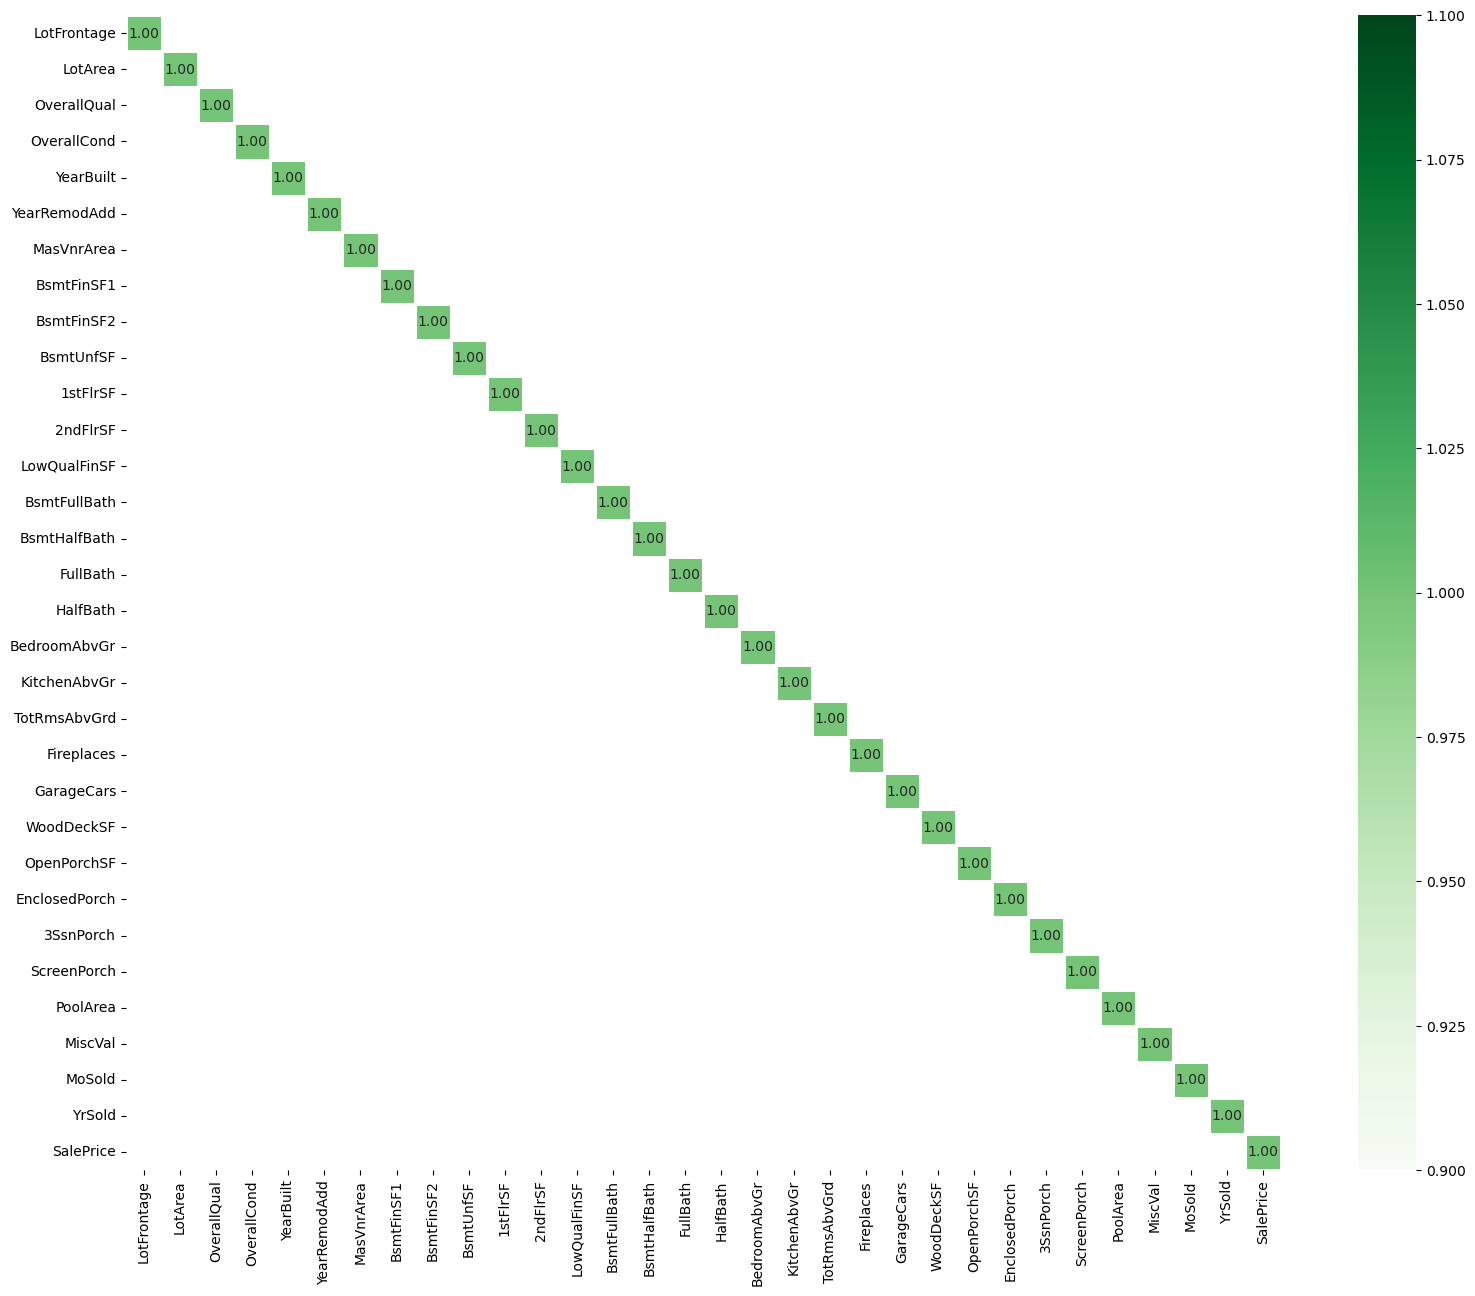

In [279]:
threshold = 0.8

correlation_matrix = train.corr(numeric_only=True)

plt.figure(figsize=(20, 15))
sns.heatmap(correlation_matrix, 
            mask=correlation_matrix<threshold, 
            annot = True,
            linewidths = 2,
            fmt = ".2f",
            square = True,
            cmap='Greens')

### High Inter Correlated Features (T=0.8)

In [281]:
threshold = 0.8
high_corr_pairs = []

# Loop through each pair of features in the correlation matrix
for feature_col in correlation_matrix.columns:
    for feature_row in correlation_matrix.columns:
        if feature_row == feature_col:
            continue
        correlation_value = abs(correlation_matrix.loc[feature_row, feature_col])
        if correlation_value > threshold:
            high_corr_pairs.append((feature_row, feature_col, correlation_value))

high_corr_train = pd.DataFrame(high_corr_pairs, columns=["feature_row", "feature_col", "Correlation"])
high_corr_train = high_corr_train.sort_values(by="Correlation", ascending=False).drop_duplicates(subset=["Correlation"])

print(high_corr_train)

Empty DataFrame
Columns: [feature_row, feature_col, Correlation]
Index: []


### High Correlted to SalePrice

In [285]:
saleprice_corr = correlation_matrix['SalePrice'].sort_values(ascending=False)
saleprice_corr

SalePrice        1.000000
OverallQual      0.790982
GarageCars       0.640409
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePrice, dtype: float64

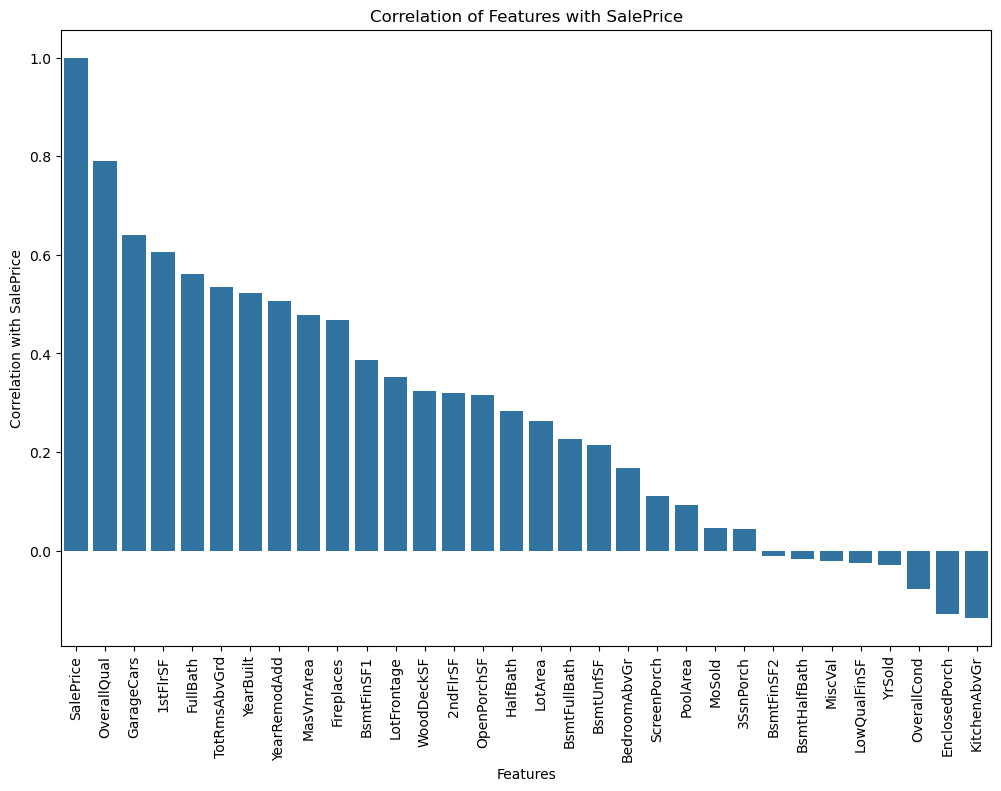

In [287]:
plt.figure(figsize=(12, 8))
sns.barplot(x=saleprice_corr.index, y=saleprice_corr.values)
plt.xticks(rotation=90)
plt.xlabel('Features')
plt.ylabel('Correlation with SalePrice')
plt.title('Correlation of Features with SalePrice')
plt.show()

## Missing Values

In [289]:
# Check missing values percentage
missing = pd.DataFrame(train.isnull().sum().sort_values(ascending=False))
missing.columns = ["Counts"]
missing = missing.loc[(missing != 0).any(axis=1)]

missing["Percentage"] = missing[0:] / 1460
missing.style.background_gradient("Greens")

,Counts,Percentage
LotFrontage,259,0.177397
GarageType,81,0.055479
GarageCond,81,0.055479
GarageFinish,81,0.055479
GarageQual,81,0.055479
BsmtFinType2,38,0.026027
BsmtExposure,38,0.026027
BsmtFinType1,37,0.025342
BsmtCond,37,0.025342
BsmtQual,37,0.025342


## Scatter Plot (X=feature, y=SalePrice)

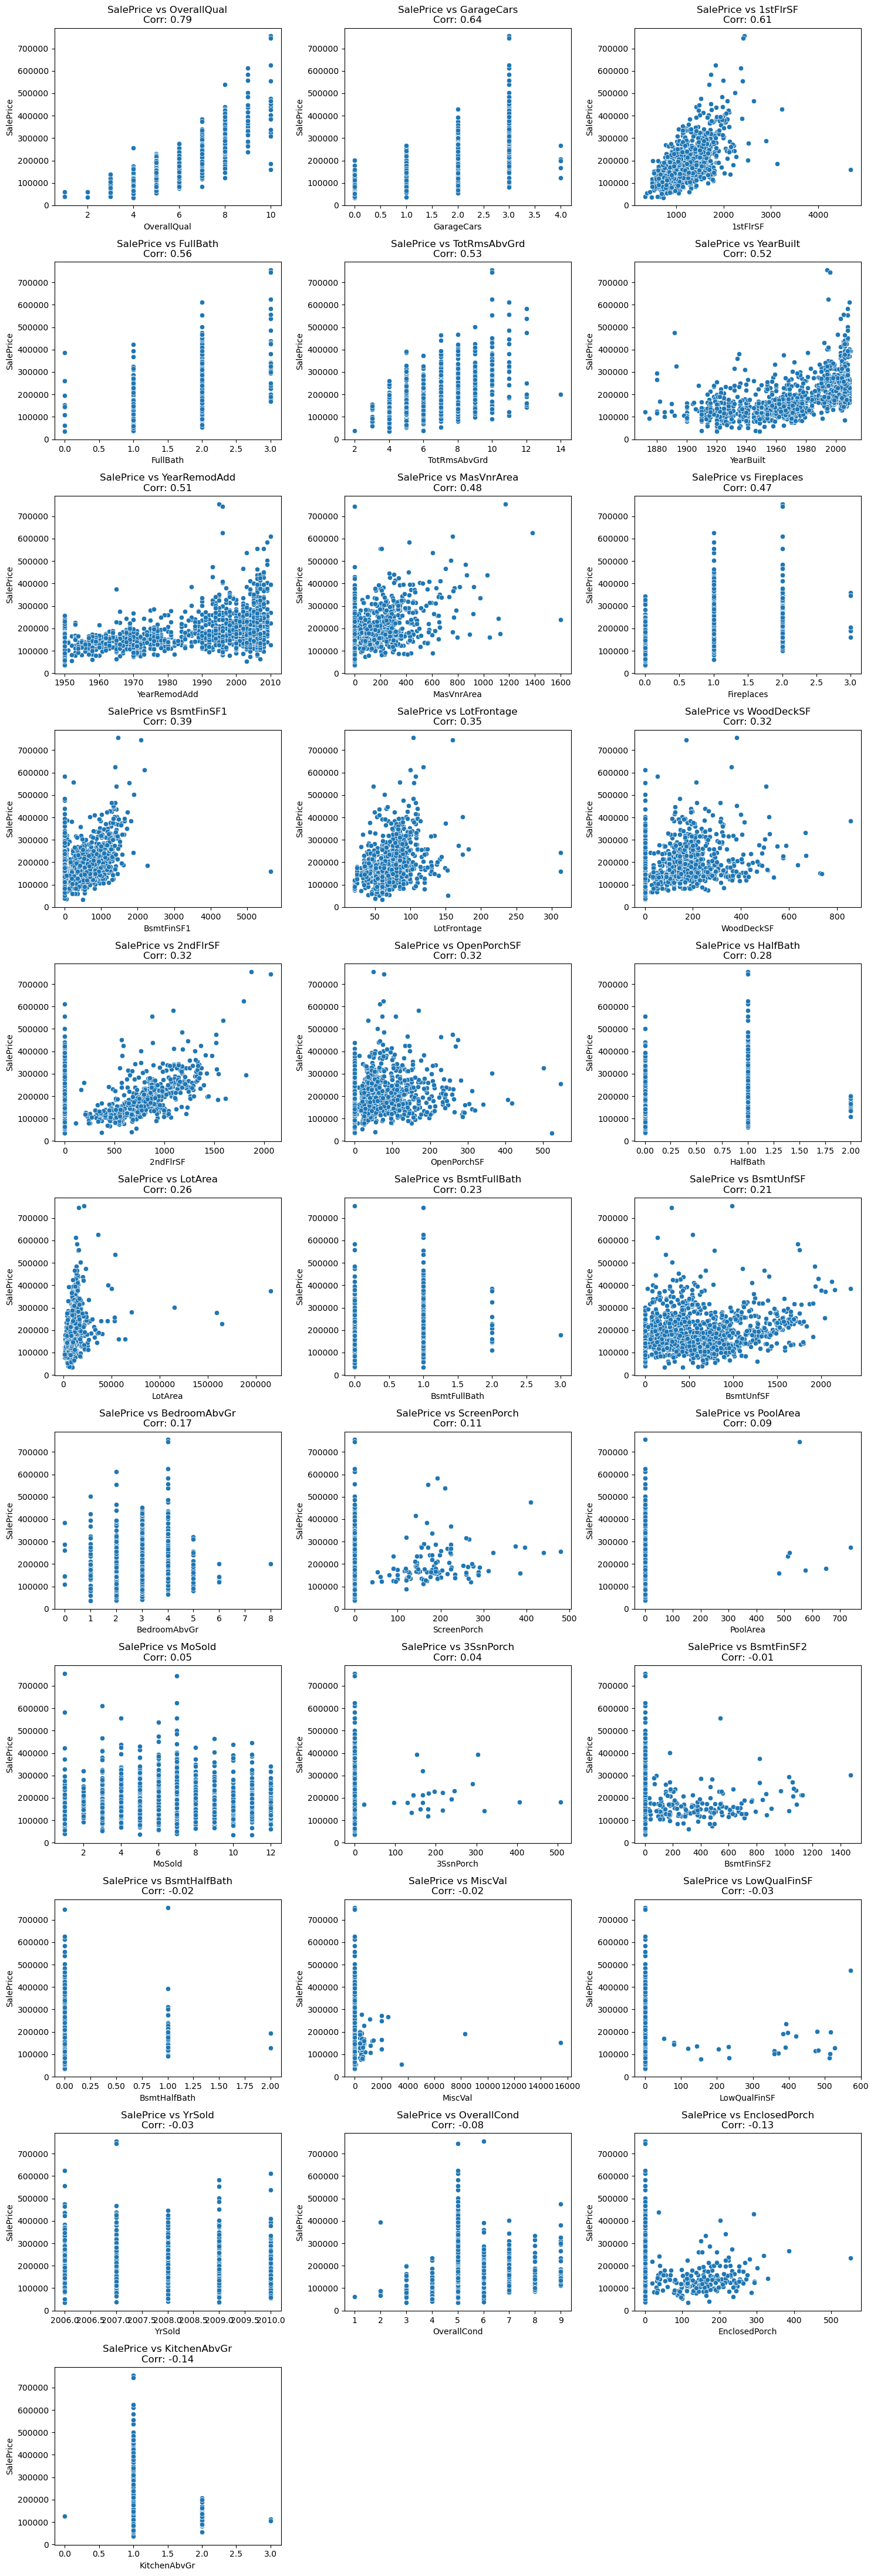

In [293]:
import math

# Assume correlation_matrix has been computed and is available
saleprice_corr = correlation_matrix['SalePrice'].sort_values(ascending=False)

# Remove SalePrice itself from the features list
features = saleprice_corr.drop('SalePrice').index.tolist()

# Calculate grid dimensions: 3 plots per row
num_plots = len(features)
cols = 3
rows = math.ceil(num_plots / cols)

# Create the subplots grid
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
axes = axes.flatten()  # Flatten in case of a 2D array

# Loop through the sorted features and create scatter plots against SalePrice
for i, feature in enumerate(features):
    sns.scatterplot(data=train, x=feature, y='SalePrice', ax=axes[i])
    # Optionally, display the correlation value in the title
    axes[i].set_title(f'SalePrice vs {feature}\nCorr: {saleprice_corr[feature]:.2f}')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('SalePrice')

# Remove any unused subplots (if total features is not a multiple of 3)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Pairplot of TOP 5 correlated Features

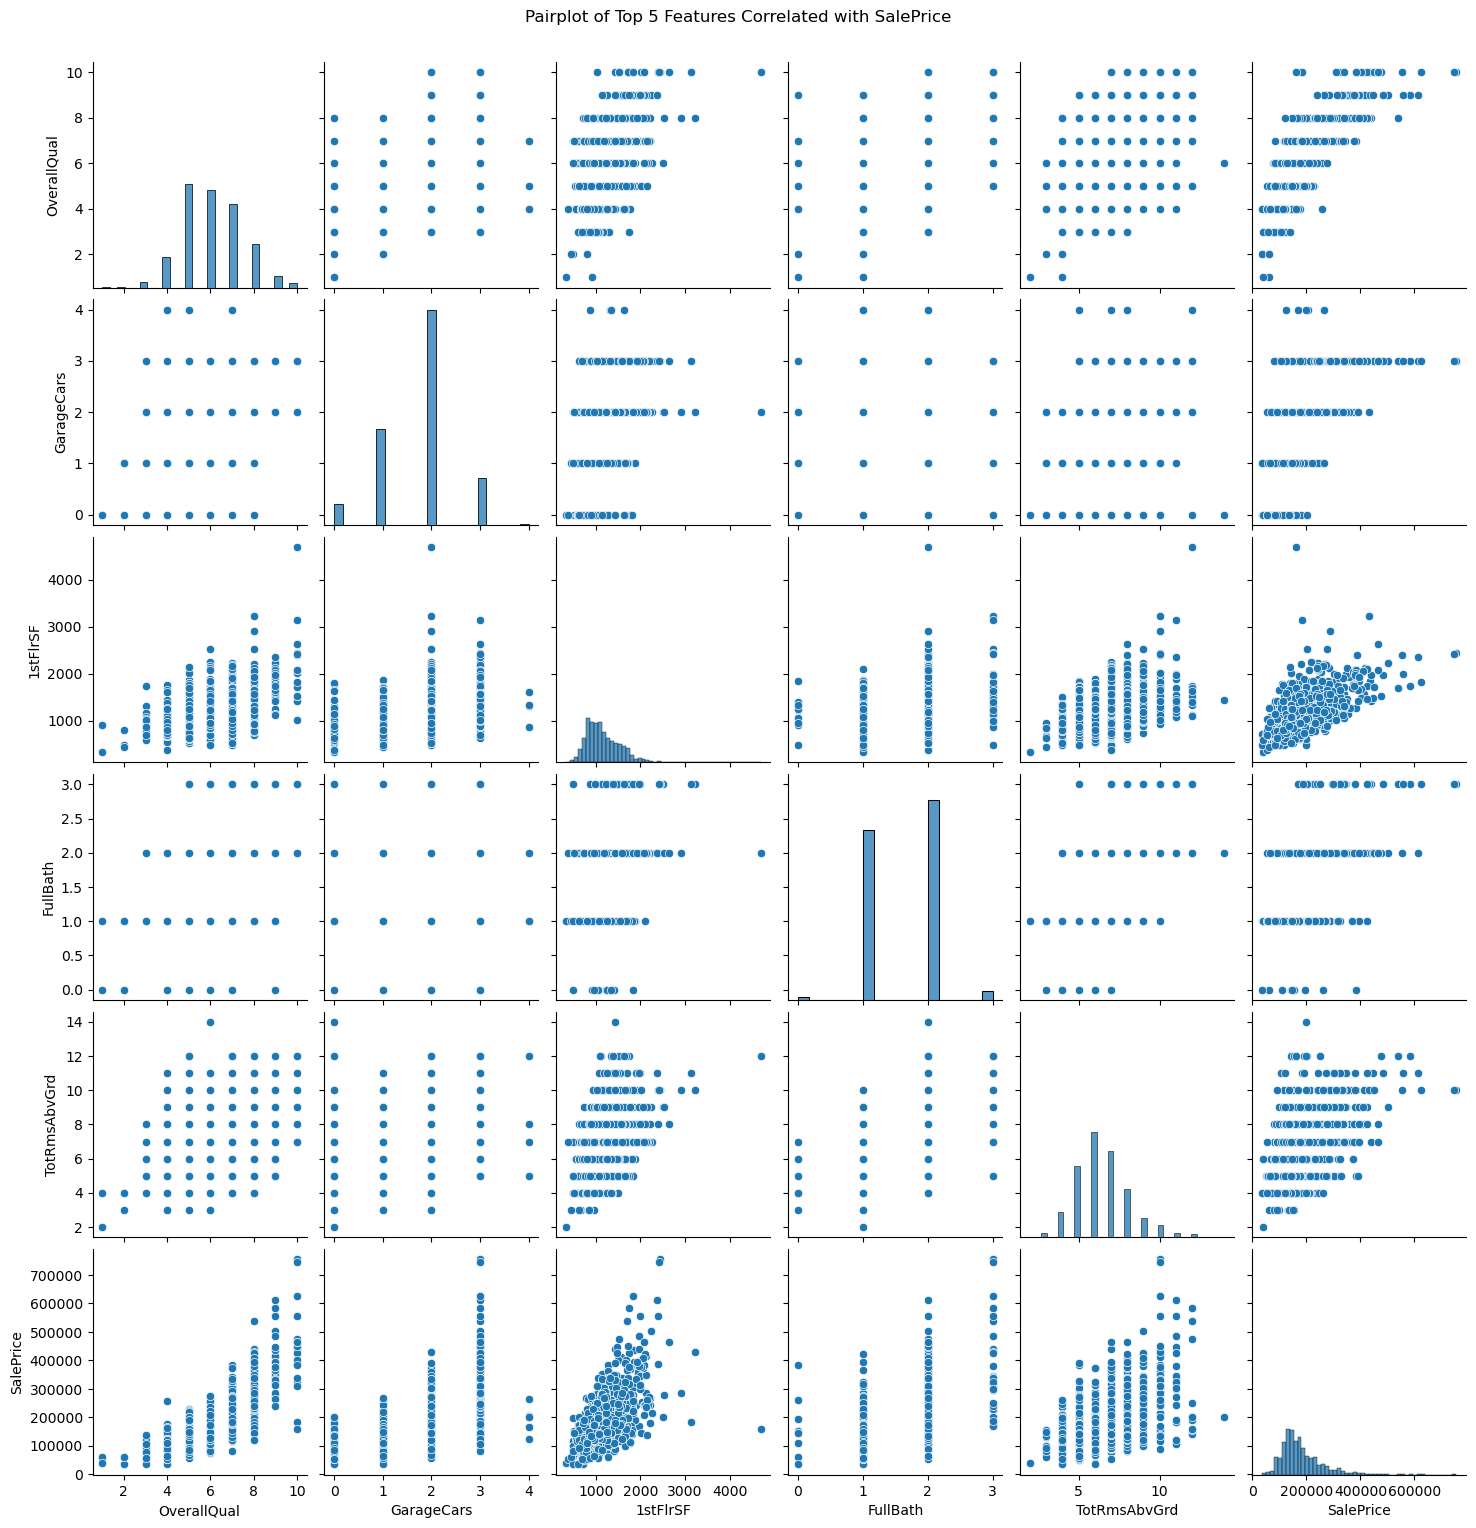

In [295]:
import seaborn as sns
import matplotlib.pyplot as plt

# Assume correlation_matrix has been computed
saleprice_corr = correlation_matrix['SalePrice'].sort_values(ascending=False)

# Get the top 5 features correlated with SalePrice (excluding SalePrice itself)
top5_features = saleprice_corr.drop('SalePrice').head(5).index.tolist()

# Create a list of columns to include in the pairplot (including SalePrice)
cols = top5_features + ['SalePrice']

# Generate the pairplot
sns.pairplot(train[cols])
plt.suptitle("Pairplot of Top 5 Features Correlated with SalePrice", y=1.02)
plt.show()

# DATA CLEANING

# FEATURE ENGINEERING

# Preprocessing

### Drop multi-collinearity

In [301]:
drop_list_multi_coll = ["GarageYrBlt", "GarageArea", "GrLivArea", "TotalBsmtSF"]

### Drop Top 6 missings

In [303]:
drop_list_missing = ["PoolQC", "MiscFeature", "Alley", "Fence", "MasVnrType","FireplaceQu"]

In [304]:
drop_list = drop_list_multi_coll + drop_list_missing
train = train.drop(columns=[col for col in drop_list if col in train.columns], errors='ignore')

In [305]:
# Remove the variables from the feature lists
numerical_continuous_features = [
    feature for feature in numerical_continuous_features if feature not in drop_list
]
numerical_discrete_features = [
    feature for feature in numerical_discrete_features if feature not in drop_list
]
ordinal_categorical_features = [
    feature for feature in ordinal_categorical_features if feature not in drop_list
]
nominal_categorical_features = [
    feature for feature in nominal_categorical_features if feature not in drop_list
]

# Remove the variables from the ordinal_mappings dictionary (if present)
for feature in drop_list:
    ordinal_mappings.pop(feature, None)

# Pipeline 

### Pipelines for Each Group

In [308]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,WOEEncoder, OneHotEncoder, OrdinalEncoder, RobustScaler
from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin

class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower_quantile=0.05, upper_quantile=0.95):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        self.lower_ = np.percentile(X, self.lower_quantile * 100, axis=0)
        self.upper_ = np.percentile(X, self.upper_quantile * 100, axis=0)
        return self

    def transform(self, X):
        return np.clip(X, self.lower_, self.upper_)
    
    def get_feature_names_out(self, input_features=None):
        # Simply return the input feature names unchanged.
        return input_features
        
# Pipeline for numerical continuous features: impute missing values with the median, then use Winsorize, then robust scale.
numerical_continuous_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('winsorizer', Winsorizer(lower_quantile=0.05, upper_quantile=0.95)),
    ('scaler', RobustScaler())
])

# Pipeline for numerical discrete features: impute missing values with the most frequent value, then scale.
numerical_discrete_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler())
])


# Pipeline for ordinal categorical features: impute missing values, then encode ordinally using our custom category orders.
ordinal_categories = [
    list(sorted(ordinal_mappings[feature], key=ordinal_mappings[feature].get))
    for feature in ordinal_categorical_features
]

ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal_encoder', OrdinalEncoder(categories=ordinal_categories))
])

# Pipeline for nominal categorical features: impute missing values and then apply one-hot encoding.
nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    #('onehot', OneHotEncoder(handle_unknown='ignore'))
    ('woe', WOEEncoder())
])

ImportError: cannot import name 'WOEEncoder' from 'sklearn.preprocessing' (/opt/anaconda3/lib/python3.11/site-packages/sklearn/preprocessing/__init__.py)

### Combine All Pipelines into a ColumnTransformer


In [ ]:
preprocessor = ColumnTransformer([
    ('num_cont', numerical_continuous_pipeline, numerical_continuous_features),
    ('num_disc', numerical_discrete_pipeline, numerical_discrete_features),
    ('ordinal', ordinal_pipeline, ordinal_categorical_features),
    ('nominal', nominal_pipeline, nominal_categorical_features)
])


set_config(display="diagram")
preprocessor

# Multivariate analysis

In [ ]:
# Process training data (assuming train DataFrame is already loaded)
processed_train_data = preprocessor.fit_transform(train)

# Attempt to retrieve feature names; requires a recent version of scikit-learn
feature_names = preprocessor.get_feature_names_out()

# Create a DataFrame from the processed data.
# If the output is sparse, convert it to dense first.
processed_train_df = pd.DataFrame(
    processed_train_data.todense() if hasattr(processed_train_data, "todense") else processed_train_data,
    columns=feature_names
)
# Add the target variable for plotting
processed_train_df['SalePrice'] = train['SalePrice'].values

# For clarity, we will separate the processed ordinal and nominal features.
# They should have names starting with "ordinal__" and "nominal__", respectively.
ordinal_cols = [col for col in feature_names if col.startswith("ordinal__")]
nominal_cols = [col for col in feature_names if col.startswith("nominal__")]

"""
# Plotting ordinal categorical features (e.g. KitchenQual, ExterQual, etc.)
for col in ordinal_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=processed_train_df[col], y=processed_train_df['SalePrice'])
    plt.title(f"SalePrice vs Processed {col}")
    plt.xlabel(col)
    plt.ylabel("SalePrice")
    plt.tight_layout()
    plt.show()

# Plotting nominal categorical features
# One-hot encoded features are binary (0 or 1); we can view how SalePrice distributes when the indicator is 1.
for col in nominal_cols:
    plt.figure(figsize=(8, 4))
    # Convert to integer for clarity (0 or 1)
    sns.boxplot(x=processed_train_df[col].astype(int), y=processed_train_df['SalePrice'])
    plt.title(f"SalePrice vs Processed {col}")
    plt.xlabel(col + " (0 or 1)")
    plt.ylabel("SalePrice")
    plt.tight_layout()
    plt.show()

"""

In [ ]:
# Fit LassoCV
lasso = LassoCV(cv=5, random_state=42).fit(processed_train_data, train['SalePrice'])
# Check coefficients
coef = lasso.coef_
print("Number of coefficients close to zero:", np.sum(np.abs(coef) < 1e-4))

# Adjust threshold: use a fraction of the maximum absolute coefficient
threshold_value = 0.1 * np.max(np.abs(coef))
selector = SelectFromModel(lasso, prefit=True, threshold=threshold_value)
selected_train_data = selector.transform(processed_train_data)
print("Selected features shape:", selected_train_data.shape)

In [ ]:
processed_train_data.shape

In [ ]:
# --- Ridge Regression with Selected Features ---
# Define a grid of alpha values and compute CV RMSE
alphas = np.logspace(-3, 2, 50)
rmse_scores = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    neg_mse = cross_val_score(ridge, selected_train_data, train['SalePrice'],
                              cv=40, scoring='neg_mean_squared_error')
    rmse = np.sqrt(-neg_mse).mean()
    rmse_scores.append(rmse)

best_index = np.argmin(rmse_scores)
best_alpha = alphas[best_index]
best_rmse = rmse_scores[best_index]
print(f"Best alpha: {best_alpha:.4f}, RMSE: {best_rmse:.4f}")

# Plotting the performance curve
plt.figure(figsize=(8, 6))
plt.plot(alphas, rmse_scores, marker='o')
plt.xscale('log')
plt.xlabel("Alpha (log scale)")
plt.ylabel("Average RMSE (40-fold CV)")
plt.title("Ridge CV - RMSE vs. Alpha (Selected Features)")
tick_values = [0.001, 0.01, 0.1, 1, 10, 100]
plt.xticks(tick_values, tick_values)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

# MODEL BUILDING

In [312]:
processed_train_data = preprocessor.fit_transform(train)

Best alpha: 7.5431, RMSE: 29758.8674


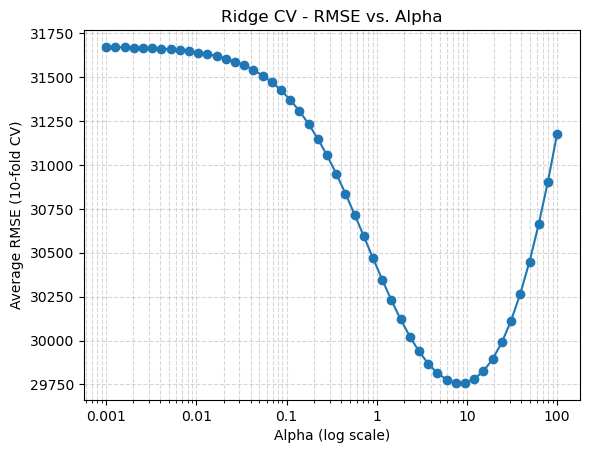

In [314]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

# 生成从 10^-3 到 10^2 共 50 个 alpha 值
alphas = np.logspace(-3, 2, 50)
test_scores = []

for alpha in alphas:
    clf = Ridge(alpha=alpha)
    neg_mse = cross_val_score(clf,
                              processed_train_data,
                              train['SalePrice'],
                              cv=40,
                              scoring='neg_mean_squared_error')
    rmse = np.sqrt(-neg_mse)
    test_scores.append(rmse.mean())

# 找到使 RMSE 最小的 alpha
best_index = np.argmin(test_scores)
best_alpha = alphas[best_index]
best_score = test_scores[best_index]
print(f"Best alpha: {best_alpha:.4f}, RMSE: {best_score:.4f}")

# 绘制 alpha 与 RMSE 之间的关系
plt.plot(alphas, test_scores, marker='o')
plt.xscale('log')  # 使用对数刻度
plt.xlabel("Alpha (log scale)")
plt.ylabel("Average RMSE (10-fold CV)")
plt.title("Ridge CV - RMSE vs. Alpha")

# 设置刻度(可根据需要调整或增加更多刻度)
tick_values = [0.001, 0.01, 0.1, 1, 10, 100]
plt.xticks(tick_values, tick_values)

plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()


In [52]:
# Generate an instance of your model; be sure to specify the alpha value, which will control the regularization
# term applied to the loss function
lasso_reg = Ridge(alpha=0.001, max_iter=100000)
lasso_reg.fit(processed_train_data, train['SalePrice'])

Ridge(alpha=0.001, max_iter=100000)

# Prediction

# Validation

In [98]:
X_train = train.drop('SalePrice', axis=1)
y_train = train['SalePrice']


In [156]:
from sklearn.linear_model import Lasso


lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('lasso', Lasso(alpha = 7.5431, max_iter=1000000))
])

set_config(display="diagram")
lasso_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num_cont',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('winsorizer',
                                                                   Winsorizer()),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['LotFrontage', 'LotArea',
                                                   'MasVnrArea', 'BsmtFinSF1',
                                                   'BsmtFinSF2', 'BsmtUnfSF',
                                                   '1stFlrSF', '2ndFlrSF',
                                                   'LowQualFinSF', 'WoodDeckSF',
                                                   'OpenPorchSF',
                                                   'EnclosedPorch', '3SsnPorch',
                                                   'Scree...
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['MSSubClass', 'MSZoning',
                                                   'Street', 'LandContour',
                                                   'LotConfig', 'Neighborhood',
                                                   'Condition1', 'Condition2',
                                                   'BldgType', 'HouseStyle',
                                                   'RoofStyle', 'RoofMatl',
                                                   'Exterior1st', 'Exterior2nd',
                                                   'Foundation', 'Heating',
                                                   'Electrical', 'GarageType',
                                                   'SaleType',
                                                   'SaleCondition'])])),
                ('lasso', Lasso(alpha=7.5431, max_iter=1000000))])

In [158]:
test = pd.read_csv("input/test.csv")
# Save the test IDs for submission
test_ids = test["Id"]

# Apply the same column-dropping steps to the test data
test = test.drop(columns=[col for col in drop_list if col in test.columns], errors='ignore')

# In Kaggle test data, the target is not provided so drop "Id" and use the rest as features.
X_test = test.drop("Id", axis=1)

# ------------------------------
# 3. Make Predictions & Create Submission File
# ------------------------------
predictions = lasso_pipeline.predict(X_test)

submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": predictions
})

submission.to_csv("submission.csv", index=False)
print("Submission file saved as submission.csv")

Submission file saved as submission.csv
